# Mountain Car: Reinforcement Learning

This work studies value iteration, model-based learning, Q-learning and safe exploration using the Mountain Car problem.

## 1. Environment

The state is the car's position and velocity. The three actions are accelerate left, do nothing, and accelerate right. The standard environment gives a reward of -1 per step and ends when the car reaches the goal or the step limit.

In [1]:
import math
import random
from collections import defaultdict
from itertools import product

import gymnasium as gym
import numpy as np

random.seed(42)
np.random.seed(42)

env = gym.make("MountainCar-v0")
observation, info = env.reset(seed=42)
print("Initial state (position, velocity):", observation)
print("Number of actions:", env.action_space.n)
print("Action meanings: 0=left, 1=neutral, 2=right")
env.close()

Initial state (position, velocity): [-0.4452088  0.       ]
Number of actions: 3
Action meanings: 0=left, 1=neutral, 2=right


## 2. Problem 1: Value iteration

For states -2, -1, 0, +1 and +2, with terminal states -2 and +2, the Bellman update is

\[V_i(s)=\max_a\sum_{s'}T(s'|s,a)igl(R(s,a,s')+V_{i-1}(s')igr),\quad \gamma=1.\]

The program below applies the two requested updates and derives the policy from \(V_2^*\).

In [2]:
states = [-2, -1, 0, 1, 2]
actions = [1, 2]
terminals = {-2, 2}

def number_line_transitions(state, action):
    backward_probability = 0.8 if action == 1 else 0.7
    outcomes = []
    for probability, next_state in [
        (backward_probability, state - 1),
        (1 - backward_probability, state + 1),
    ]:
        reward = 10 if next_state == -2 else 50 if next_state == 2 else -5
        outcomes.append((probability, next_state, reward))
    return outcomes

def value_iteration_updates(iterations):
    values = {state: 0.0 for state in states}
    history = [values.copy()]
    for _ in range(iterations):
        updated = {state: 0.0 for state in terminals}
        for state in states:
            if state in terminals:
                continue
            action_values = []
            for action in actions:
                q = sum(
                    probability * (reward + values[next_state])
                    for probability, next_state, reward in number_line_transitions(state, action)
                )
                action_values.append(q)
            updated[state] = max(action_values)
        values = updated
        history.append(values.copy())
    return history

history = value_iteration_updates(2)
print("State | V1*(s) | V2*(s)")
for state in states:
    print(f"{state:>5} | {history[1][state]:>6.2f} | {history[2][state]:>6.2f}")

def greedy_policy(values):
    policy = {}
    for state in states:
        if state in terminals:
            continue
        action_values = {
            action: sum(
                probability * (reward + values[next_state])
                for probability, next_state, reward in number_line_transitions(state, action)
            )
            for action in actions
        }
        policy[state] = max(action_values, key=lambda action: (action_values[action], action))
    return policy

print("Policy from V2*:", greedy_policy(history[2]))

State | V1*(s) | V2*(s)
   -2 |   0.00 |   0.00
   -1 |   7.00 |   6.00
    0 |  -5.00 |   3.35
    1 |  11.50 |   8.00
    2 |   0.00 |   0.00
Policy from V2*: {-1: 1, 0: 2, 1: 2}


## 3. Problem 2: Transforming an MDP

Add an absorbing state \(o\). For original transitions set

\[T'(s'|s,a)=\gamma T(s'|s,a),\qquad T'(o|s,a)=1-\gamma.\]

Set \(R'(s,a,s')=R(s,a,s')/\gamma\) and \(R'(s,a,o)=0\). State \(o\) stays in itself with zero reward. The transformed Bellman update with discount 1 is the original discounted Bellman update, so both MDPs have the same optimal values on the original states.

In [3]:
def transform_transitions(original_model, discount, absorbing_state="o"):
    if not 0 < discount <= 1:
        raise ValueError("discount must be in (0, 1]")
    transformed = {}
    for state_action, outcomes in original_model.items():
        transformed[state_action] = [
            (discount * probability, next_state, reward / discount)
            for probability, next_state, reward in outcomes
        ]
        missing_probability = 1 - discount
        if missing_probability:
            transformed[state_action].append((missing_probability, absorbing_state, 0.0))
    return transformed

example_model = {("s", "a"): [(0.25, "x", 4.0), (0.75, "y", -2.0)]}
transformed_model = transform_transitions(example_model, 0.8)
print("Transformed transitions:", transformed_model[("s", "a")])
print("Probability sum:", sum(item[0] for item in transformed_model[("s", "a")]))

Transformed transitions: [(0.2, 'x', 5.0), (0.6000000000000001, 'y', -2.5), (0.19999999999999996, 'o', 0.0)]
Probability sum: 1.0


## 4. Problem 3: Model-based Monte Carlo

The agent estimates transition probabilities and mean rewards from sampled transitions. It runs value iteration after a chosen number of interactions and follows the current policy with epsilon-greedy exploration.

In [4]:
def value_iteration_model(model, discount=1.0, epsilon=1e-3):
    state_actions = defaultdict(set)
    for state, action in model:
        state_actions[state].add(action)
    values = defaultdict(float)
    while True:
        updated = defaultdict(float)
        for state, available_actions in state_actions.items():
            updated[state] = max(
                sum(
                    probability * (reward + discount * values[next_state])
                    for probability, next_state, reward in model[(state, action)]
                )
                for action in available_actions
            )
        if all(abs(updated[state] - values[state]) <= epsilon for state in state_actions):
            values = updated
            break
        values = updated
    policy = {
        state: max(
            available_actions,
            key=lambda action: (
                sum(
                    probability * (reward + discount * values[next_state])
                    for probability, next_state, reward in model[(state, action)]
                ),
                action,
            ),
        )
        for state, available_actions in state_actions.items()
    }
    return values, policy

class ModelBasedMonteCarlo:
    def __init__(self, actions, discount=1.0, update_every=100, exploration_prob=0.2):
        if update_every <= 0:
            raise ValueError("update_every must be positive")
        self.actions = list(actions)
        self.discount = discount
        self.update_every = update_every
        self.exploration_prob = exploration_prob
        self.steps = 0
        self.transition_counts = defaultdict(lambda: defaultdict(int))
        self.reward_totals = defaultdict(lambda: defaultdict(float))
        self.policy = {}

    def get_action(self, state, explore=True):
        if state not in self.policy or (explore and random.random() < self.exploration_prob):
            return random.choice(self.actions)
        return self.policy[state]

    def incorporate_feedback(self, state, action, reward, next_state):
        self.transition_counts[(state, action)][next_state] += 1
        self.reward_totals[(state, action)][next_state] += reward
        self.steps += 1
        if self.steps % self.update_every:
            return
        model = {}
        for key, counts in self.transition_counts.items():
            total = sum(counts.values())
            model[key] = [
                (count / total, next_state, self.reward_totals[key][next_state] / count)
                for next_state, count in counts.items()
            ]
        _, self.policy = value_iteration_model(model, self.discount)

agent = ModelBasedMonteCarlo(actions=[1, 2], update_every=1)
agent.incorporate_feedback(-1, 1, 10, -2)
print("Policy after observing a terminal reward:", agent.policy)

Policy after observing a terminal reward: {-1: 1}


The three training runs improved from long episodes near the step limit to shorter episodes after the transition estimates became more useful. The curves remain noisy because the estimated model depends on the state-action pairs sampled during exploration. Model-based learning may do poorly when important transitions are rarely observed, the state space is large, or the model is updated too slowly.

### Model-based value iteration — Trial 1

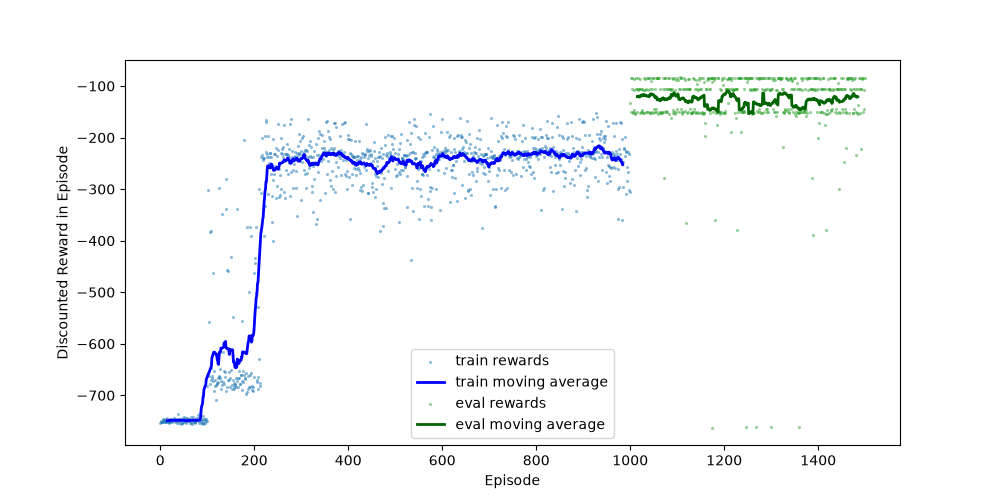

### Model-based value iteration — Trial 2

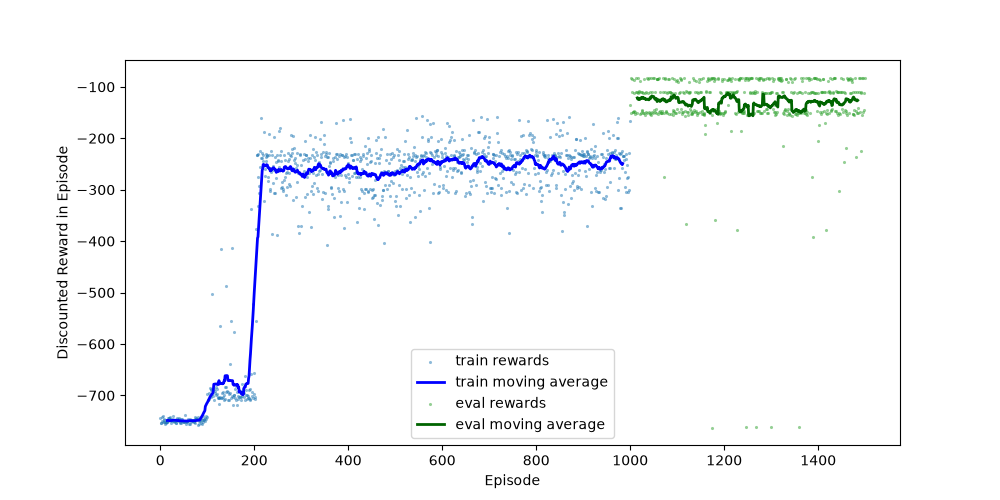

### Model-based value iteration — Trial 3

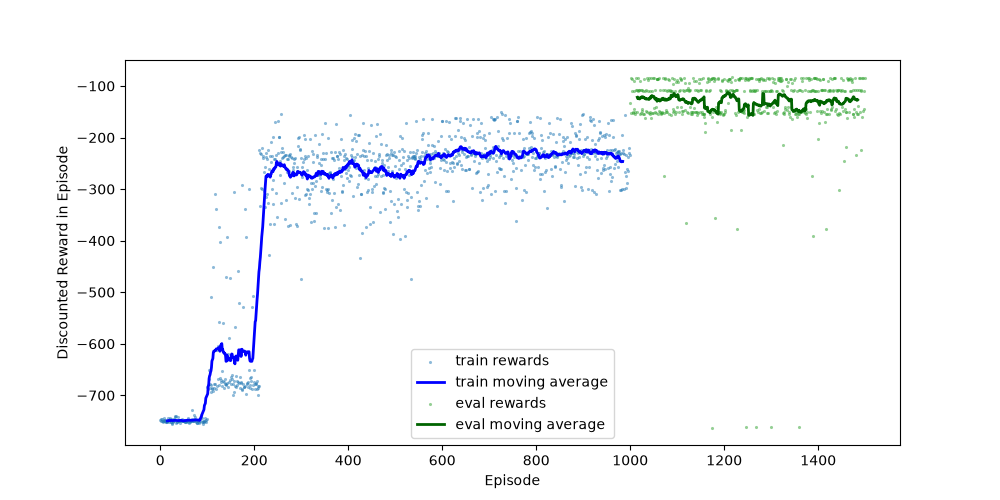

## 5. Problem 4: Q-learning

Tabular Q-learning updates the value for a state-action pair directly. With continuous states, Fourier features are used to approximate the Q-value with a weighted sum.

In [5]:
class TabularQLearning:
    def __init__(self, actions, discount=0.99, exploration_prob=0.2, initial_q=0.0):
        self.actions = list(actions)
        self.discount = discount
        self.exploration_prob = exploration_prob
        self.q = defaultdict(lambda: initial_q)

    def get_action(self, state, explore=True):
        if explore and random.random() < self.exploration_prob:
            return random.choice(self.actions)
        return max(self.actions, key=lambda action: (self.q[state, action], action))

    def incorporate_feedback(self, state, action, reward, next_state, terminal=False, learning_rate=0.1):
        future = 0.0 if terminal else max(self.q[next_state, a] for a in self.actions)
        target = reward + self.discount * future
        self.q[state, action] += learning_rate * (target - self.q[state, action])

def fourier_feature_extractor(state, max_coeff=5, scale=None):
    state = np.asarray(state, dtype=float)
    if scale is None:
        scale = np.ones_like(state)
    scaled_state = state * np.asarray(scale, dtype=float)
    coefficients = np.indices((max_coeff + 1,) * len(state)).reshape(len(state), -1).T
    return np.cos(np.pi * (coefficients @ scaled_state))

class FunctionApproxQLearning:
    def __init__(self, actions, feature_extractor, feature_dim, discount=0.999, exploration_prob=0.2):
        self.actions = list(actions)
        self.feature_extractor = feature_extractor
        self.discount = discount
        self.exploration_prob = exploration_prob
        self.weights = np.random.standard_normal((feature_dim, len(actions)))
        self.num_steps = 0

    def get_q(self, state, action):
        return float(self.feature_extractor(state) @ self.weights[:, action])

    def get_action(self, state, explore=True):
        if explore:
            self.num_steps += 1
        epsilon = 1.0 if self.num_steps < 20_000 else self.exploration_prob
        if explore and random.random() < epsilon:
            return random.choice(self.actions)
        return max(self.actions, key=lambda action: (self.get_q(state, action), action))

    def incorporate_feedback(self, state, action, reward, next_state, terminal=False):
        features = self.feature_extractor(state)
        prediction = self.get_q(state, action)
        future = 0.0 if terminal else max(self.get_q(next_state, a) for a in self.actions)
        error = reward + self.discount * future - prediction
        step_size = 0.005 * (0.99 ** (self.num_steps / 500))
        self.weights[:, action] += step_size * error * features

features = fourier_feature_extractor((0.5, 0.3), max_coeff=2)
print("Fourier feature count:", len(features))
print("Tabular Q-learning and function approximation classes are ready.")

Fourier feature count: 9
Tabular Q-learning and function approximation classes are ready.


The tabular agent generally learned more consistently in this task because the discretized state space was small enough to visit repeatedly. The Fourier approximation generalizes between nearby continuous states, but may underfit the nonlinear dynamics and updates can affect several regions of the state space. Function approximation can be more useful when exploration time or memory is limited, or when the state space is too large to represent as a table.

### Tabular Q-learning — Trial 1

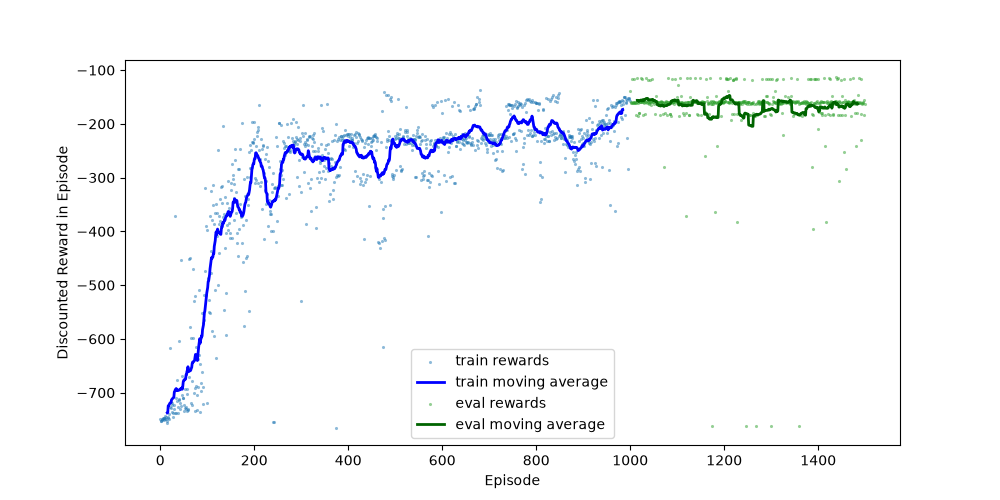

### Tabular Q-learning — Trial 2

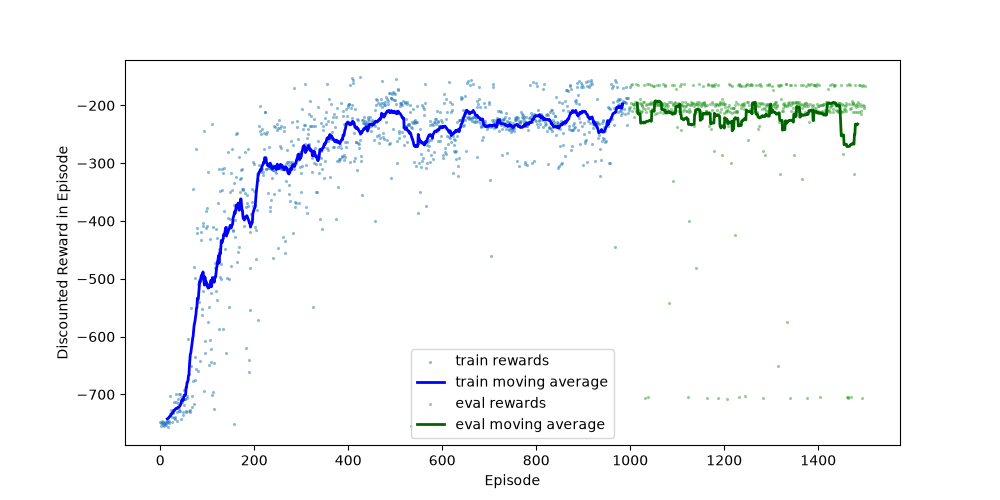

### Tabular Q-learning — Trial 3

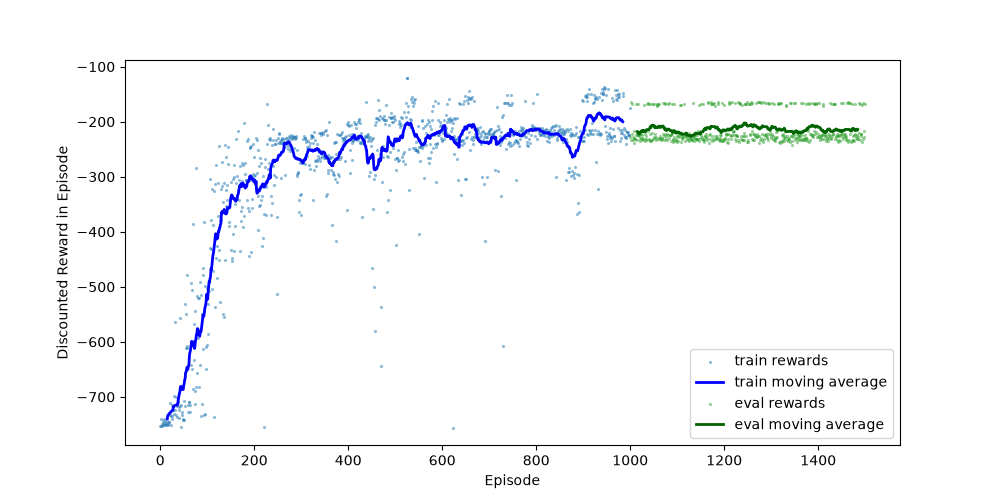

### Function approximation — Trial 1

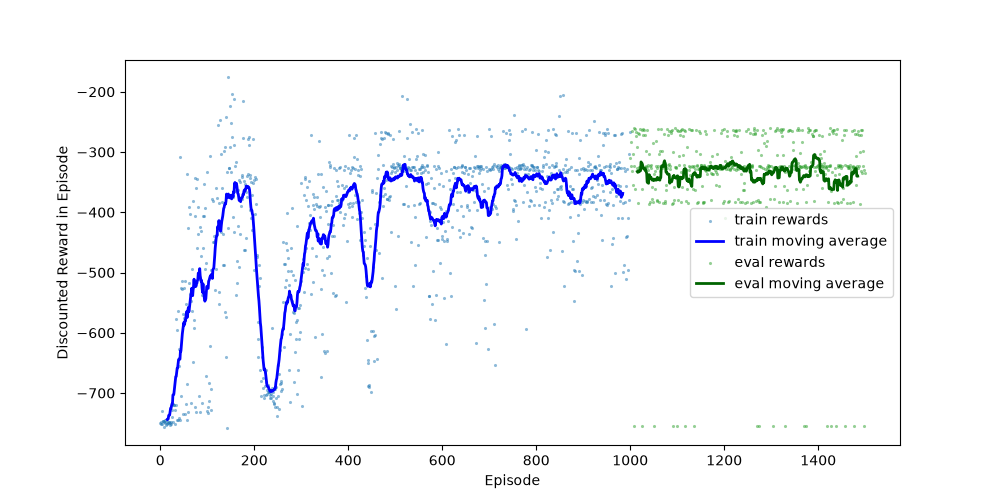

### Function approximation — Trial 2

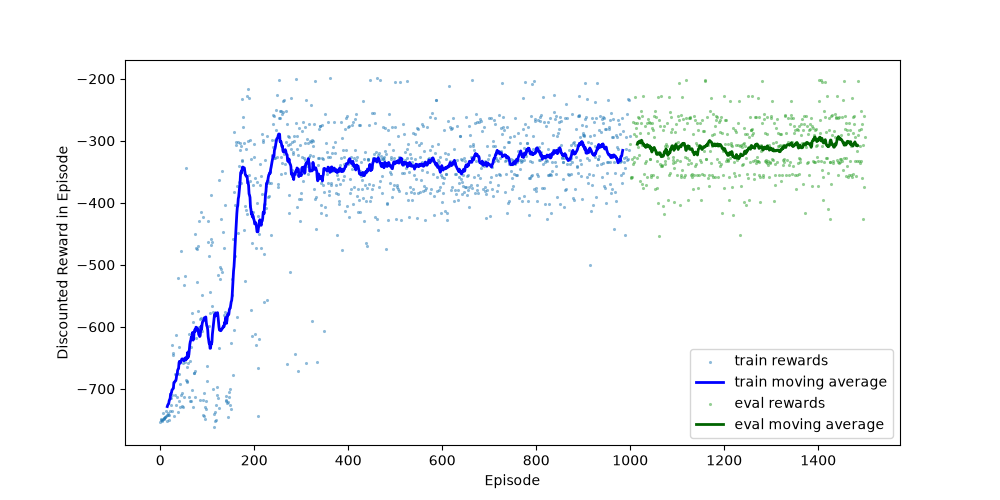

### Function approximation — Trial 3

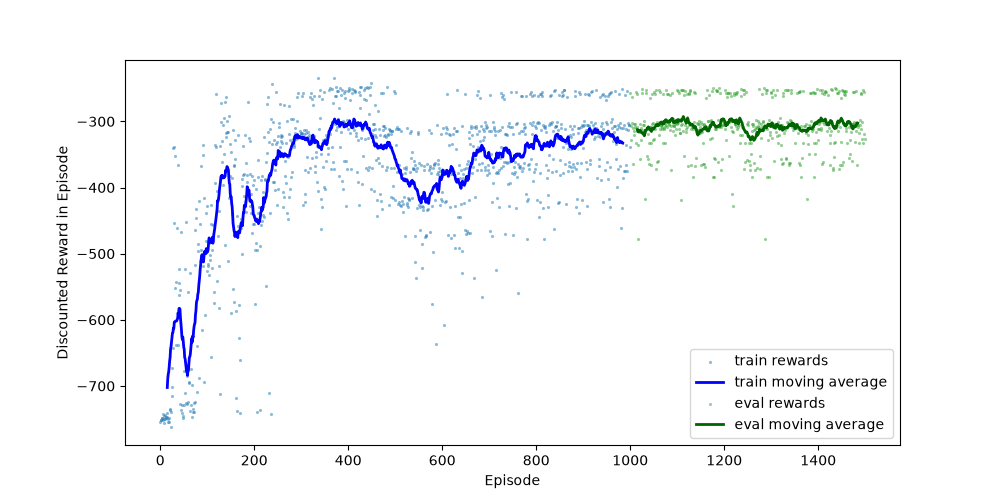

## 6. Problem 5: Safe exploration

The environment limits velocity by clipping the updated value to \([-	exttt{max_speed},	exttt{max_speed}]\). The constrained learner also filters actions using the next-velocity equation:

In [6]:
class ConstrainedQLearning(FunctionApproxQLearning):
    def __init__(self, *args, force=0.001, gravity=0.0025, velocity_threshold=0.065, **kwargs):
        super().__init__(*args, **kwargs)
        self.force = force
        self.gravity = gravity
        self.velocity_threshold = velocity_threshold

    def valid_actions(self, state):
        position, velocity = state
        return [
            action for action in self.actions
            if velocity + (action - 1) * self.force - math.cos(3 * position) * self.gravity
            < self.velocity_threshold
        ]

    def get_action(self, state, explore=True):
        valid = self.valid_actions(state)
        if not valid:
            return None
        if explore and random.random() < self.exploration_prob:
            return random.choice(valid)
        return max(valid, key=lambda action: (self.get_q(state, action), action))

constrained = ConstrainedQLearning(
    actions=[0, 1, 2],
    feature_extractor=lambda state: fourier_feature_extractor(state, max_coeff=5, scale=[1, 15]),
    feature_dim=36,
    velocity_threshold=0.065,
)
state = (-0.5, 0.0649)
print("Valid actions:", constrained.valid_actions(state))
print("Selected safe action:", constrained.get_action(state, explore=False))

Valid actions: [0, 1]
Selected safe action: 1


A very large maximum speed does not necessarily change the learned behavior if the useful trajectories rarely need to exceed the original speed limit. The action-filtered policy can differ because it removes actions that would cross the unsafe velocity threshold.

### Autonomous-vehicle example

**MDP A — unrestricted exploration.** State includes position, speed, lane, traffic-light status, pedestrians, nearby vehicles and the road speed limit. Actions include steering, accelerating, braking and changing lanes. Reward includes progress and penalties for collisions and traffic violations. Epsilon-greedy exploration on public roads can expose pedestrians and other road users to unsafe trial-and-error.

**MDP B — safety-filtered exploration.** Use the same state and actions, but reject actions that violate speed limits, red lights, pedestrian safety zones or safe braking limits. The reward gives dominant penalties to collisions and violations. Explore first in simulation and closed courses, and use a conservative policy with a controlled-stop fallback on public roads. These restrictions reduce the chance of harm during learning.

## Conclusion

The experiments compare planning with an estimated model, tabular Q-learning and Fourier function approximation. They also show how restricting the available actions can reduce unsafe exploration.